# Bankruptcy Prediction — Exploratory Data Analysis

## Project Overview

This project focuses on predicting whether a company is likely to go bankrupt using financial ratio data.

The dataset contains financial information from Taiwanese companies and includes 95 columns. The target variable is `Bankrupt`.

In this notebook, we perform Exploratory Data Analysis (EDA) to understand the dataset before data cleaning and model building.

### Objectives of this notebook

- Load and inspect the dataset
- Understand the dataset size and structure
- Check data types
- Analyze the target variable
- Identify class imbalance
- Check missing values and duplicate records
- View basic statistical information
- Explore important financial features visually

### Target Variable

`Bankrupt`

- `0` = Healthy company
- `1` = Bankrupt company

## 1. Import Required Libraries

First, we import the Python libraries required for data analysis and visualization.

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warning messages for cleaner notebook output
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

# Visualization style
sns.set_style("whitegrid")

%matplotlib inline

## 2. Load the Dataset

The dataset is stored inside the `data` folder.

Since this notebook is inside the `notebooks` folder, we use `../data/bankruptcy.csv` to access the dataset.

In [2]:
# Load the dataset
df = pd.read_csv("../data/bankruptcy.csv")

# Display dataset shape
print("Dataset loaded successfully.")
print("Shape:", df.shape)

# Display first five rows
df.head()

Dataset loaded successfully.
Shape: (6819, 95)


,Bankrupt,ROA_C_Before_Interest_Depreciation,ROA_A_Before_Interest_After_Tax,ROA_B_Before_Interest_Depreciation_After_Tax,Operating_Gross_Margin,Realized_Sales_Gross_Margin,Operating_Profit_Rate,PreTax_Net_Interest_Rate,AfterTax_Net_Interest_Rate,NonIndustry_Income_Expenditure_Revenue,Continuous_Interest_Rate_After_Tax,Operating_Expense_Rate,R&D_Expense_Rate,Cash_Flow_Rate,InterestBearing_Debt_Interest_Rate,Tax_Rate_A,Net_Value_Per_Share_B,Net_Value_Per_Share_A,Net_Value_Per_Share_C,Persistent_EPS_Last_4_Seasons,Cash_Flow_Per_Share,Revenue_Per_Share,Operating_Profit_Per_Share,Net_Profit_Before_Tax_Per_Share,Realized_Sales_Gross_Profit_Growth_Rate,Operating_Profit_Growth_Rate,AfterTax_Net_Profit_Growth_Rate,Regular_Net_Profit_Growth_Rate,Continuous_Net_Profit_Growth_Rate,Total_Asset_Growth_Rate,Net_Value_Growth_Rate,Total_Asset_Return_Growth_Rate,Cash_Reinvestment_Percent,Current_Ratio,Quick_Ratio,Interest_Expense_Ratio,Total_Debt_to_Net_Worth,Debt_Ratio_Percent,Net_Worth_to_Assets,LongTerm_Fund_Suitability_Ratio_A,Borrowing_Dependency,Contingent_Liabilities_to_Net_Worth,Operating_Profit_to_PaidIn_Capital,Net_Profit_Before_Tax_to_PaidIn_Capital,Inventory_Accounts_Receivable_to_Net_Value,Total_Asset_Turnover,Accounts_Receivable_Turnover,Average_Collection_Days,Inventory_Turnover_Rate,Fixed_Assets_Turnover_Frequency,Net_Worth_Turnover_Rate,Revenue_Per_Person,Operating_Profit_Per_Person,Allocation_Rate_Per_Person,Working_Capital_to_Total_Assets,Quick_Assets_to_Total_Assets,Current_Assets_to_Total_Assets,Cash_to_Total_Assets,Quick_Assets_to_Current_Liability,Cash_to_Current_Liability,Current_Liability_to_Assets,Operating_Funds_to_Liability,Inventory_to_Working_Capital,Inventory_to_Current_Liability,Current_Liabilities_to_Liability,Working_Capital_to_Equity,Current_Liabilities_to_Equity,LongTerm_Liability_to_Current_Assets,Retained_Earnings_to_Total_Assets,Total_Income_to_Total_Expense,Total_Expense_to_Assets,Current_Asset_Turnover_Rate,Quick_Asset_Turnover_Rate,Working_Capital_Turnover_Rate,Cash_Turnover_Rate,Cash_Flow_to_Sales,Fixed_Assets_to_Assets,Current_Liability_to_Liability,Current_Liability_to_Equity,Equity_to_LongTerm_Liability,Cash_Flow_to_Total_Assets,Cash_Flow_to_Liability,CFO_to_Assets,Cash_Flow_to_Equity,Current_Liability_to_Current_Assets,Liability_Assets_Flag,Net_Income_to_Total_Assets,Total_Assets_to_GNP_Price,NoCredit_Interval,Gross_Profit_to_Sales,Net_Income_to_Stockholders_Equity,Liability_to_Equity,DFL,Interest_Coverage_Ratio,Equity_to_Liability
0,No,0.5718,0.6424,0.6347,0.6262,0.6262,0.9992,0.7977,0.8097,0.3036,0.7819,0.0003,0.0003,0.4778,0.0006,0.0015,0.2163,0.2163,0.2163,0.2580,0.3322,0.0268,0.1291,0.2057,0.0221,0.8480,0.6894,0.6894,0.2176,8550000000.0000,0.0006,0.2641,0.3809,0.0148,0.0135,0.6306,0.0017,0.0457,0.9543,0.0066,0.3696,0.0054,0.1281,0.2035,0.3963,0.1154,0.0010,0.0060,0.0003,0.0004,0.0245,0.0262,0.4156,0.0080,0.8141,0.3792,0.3891,0.2145,0.0139,0.0227,0.0498,0.3890,0.2770,0.0025,0.9808,0.7350,0.3277,0.0000,0.9538,0.0026,0.0310,0.0001,0.0001,0.5940,0.0002,0.6715,0.1262,0.9808,0.3277,0.1109,0.5966,0.4350,0.6407,0.3094,0.0198,0,0.8544,0.0078,0.6240,0.6262,0.8433,0.2760,0.0268,0.5652,0.0840
1,No,0.4946,0.5498,0.5434,0.6021,0.6021,0.9990,0.7974,0.8093,0.3035,0.7816,0.0001,5600000000.0000,0.4591,0.0008,0.0824,0.1731,0.1731,0.1731,0.2199,0.3122,0.0526,0.1014,0.1746,0.0224,0.8482,0.6899,0.6899,0.2176,7150000000.0000,0.0005,0.2646,0.3651,0.0091,0.0054,0.6317,0.0088,0.1455,0.8545,0.0060,0.3725,0.0054,0.1013,0.1737,0.4106,0.2414,0.0009,0.0070,0.0001,0.0010,0.0597,0.0249,0.3940,0.0030,0.8199,0.4728,0.7421,0.0834,0.0056,0.0029,0.1517,0.3339,0.2775,0.0094,0.9920,0.7375,0.3340,3490000000.0000,0.9341,0.0023,0.0362,0.0001,7720000000.0000,0.5939,3900000000.0000,0.6716,0.1140,0.9920,0.3340,0.1110,0.5904,0.4501,0.5327,0.3049,0.0319,0,0.8041,0.0070,0.6237,0.6021,0.8408,0.2812,0.0272,0.5666,0.0251
2,No,0.4653,0.5156,0.5116,0.5938,0.5938,0.9990,0.7974,0.8093,0.3035,0.7815,1110000000.0000,67900000.0000,0.4630,0.0002,0.000

## 3. Dataset Size

Here, we check the number of rows and columns in the dataset.

Rows represent company records, while columns represent financial features and the target variable.

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6819
Number of columns: 95


## 2. Dataset Overview

In this section, we check the basic structure of the dataset.

This includes:

- Number of rows and columns
- Data types of the columns
- Basic statistical summary of the numerical features

This helps us understand the dataset before moving into deeper analysis.

In [4]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nData Types Count:")
print(df.dtypes.value_counts())

Dataset Shape: (6819, 95)

Number of Rows: 6819
Number of Columns: 95

Data Types Count:
float64    93
str         1
int64       1
Name: count, dtype: int64


### Observation

The dataset contains 6,819 records and 95 columns.

Most columns are numerical financial ratio features. The dataset mainly contains `float64` values, while a small number of columns are stored as `int64`.

This confirms that the dataset is mostly numerical and suitable for machine learning after proper preprocessing.

In [5]:
df.describe().T.head(20)

,count,mean,std,min,25%,50%,75%,max
ROA_C_Before_Interest_Depreciation,6819.0000,0.5052,0.0607,0.0000,0.4765,0.5027,0.5356,1.0000
ROA_A_Before_Interest_After_Tax,6819.0000,0.5586,0.0656,0.0000,0.5355,0.5598,0.5892,1.0000
ROA_B_Before_Interest_Depreciation_After_Tax,6819.0000,0.5536,0.0616,0.0000,0.5273,0.5523,0.5841,1.0000
Operating_Gross_Margin,6819.0000,0.6079,0.0169,0.0000,0.6004,0.6060,0.6139,1.0000
Realized_Sales_Gross_Margin,6819.0000,0.6079,0.0169,0.0000,0.6004,0.6060,0.6138,1.0000
Operating_Profit_Rate,6819.0000,0.9988,0.0130,0.0000,0.9990,0.9990,0.9991,1.0000
PreTax_Net_Interest_Rate,6819.0000,0.7972,0.0129,0.0000,0.7974,0.7975,0.7976,1.0000
AfterTax_Net_Interest_Rate,6819.0000,0.8091,0.0136,0.0000,0.8093,0.8094,0.8095,1.0000
NonIndustry_Income_Expenditure_Revenue,6819.0000,0.3036,0.0112,0.0000,0.3035,0.3035,0.3036,1.0000
Continuous_Interest_Rate_After_Tax,6819.0000,0.7814,0.0127,0.0000,0.7816,0.7816,0.7817,1.0000


### Statistical Summary Observation

The statistical summary shows the count, mean, standard deviation, minimum value, quartiles, and maximum value for each numerical column.

Some features have very large maximum values compared to their median values. This suggests that the dataset may contain outliers or highly skewed financial ratios.

These issues will be handled later during the data cleaning and preprocessing stage.

In [6]:
# Check duplicate rows
duplicate_rows = df.duplicated().sum()

# Check memory usage in MB
memory_usage = round(df.memory_usage(deep=True).sum() / 1024**2, 2)

print("Duplicate rows:", duplicate_rows)
print("Memory usage (MB):", memory_usage)

Duplicate rows: 0
Memory usage (MB): 5.22


## 4. Missing and Invalid Values

In this section, we check whether the dataset contains missing or invalid values.

Missing values can cause errors during analysis and machine learning model training.  
We first check for explicit missing values such as `NaN`.

In [7]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_values / len(df) * 100).round(2)

# Create missing values summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

# Keep only columns with missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

# Display result
if len(missing_summary) > 0:
    missing_summary.sort_values("Missing Values", ascending=False)
else:
    print("No missing values found in the dataset.")

No missing values found in the dataset.


### Observation

The dataset does not contain any explicit missing values.

This means there are no `NaN` values in the dataset, so missing value imputation is not required at this stage.

However, some financial datasets may contain invalid values such as infinity or extremely large values, so these will be considered later during the data cleaning stage.

## 5. Target Variable Distribution

In this section, we analyze the distribution of the target variable `Bankrupt`.

The target variable has two classes:

- `0` = Healthy company
- `1` = Bankrupt company

This step is important because bankruptcy prediction datasets are usually imbalanced.  
An imbalanced dataset means one class has many more records than the other class.

In [8]:
# Count target classes
target_counts = df["Bankrupt"].value_counts().sort_index()

# Calculate class percentages
target_percentages = (target_counts / target_counts.sum() * 100).round(2)

# Display class balance
class_balance = pd.DataFrame({
    "Class": ["Healthy", "Bankrupt"],
    "Count": target_counts.values,
    "Percentage (%)": target_percentages.values
})

class_balance

,Class,Count,Percentage (%)
0,Healthy,6599,96.7700
1,Bankrupt,220,3.2300


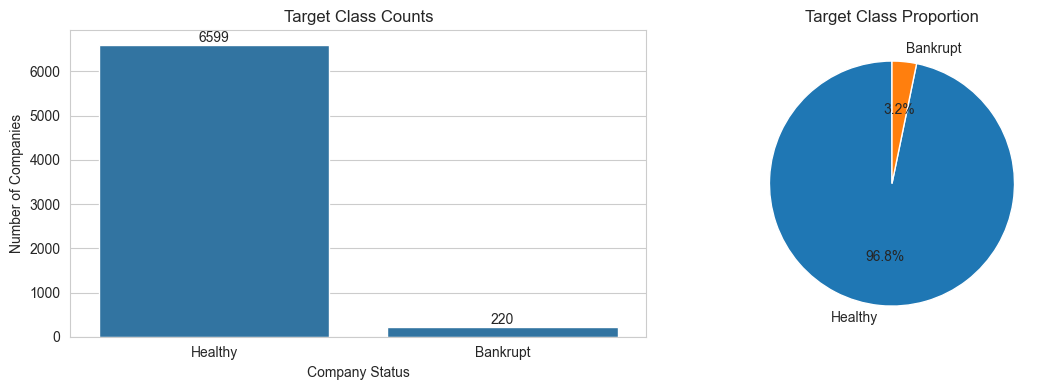

In [9]:
# Create target distribution plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
sns.countplot(x="Bankrupt", data=df, ax=axes[0])

axes[0].set_title("Target Class Counts")
axes[0].set_xlabel("Company Status")
axes[0].set_ylabel("Number of Companies")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Healthy", "Bankrupt"])

# Add count labels on bars
for container in axes[0].containers:
    axes[0].bar_label(container)

# Pie chart
axes[1].pie(
    target_counts,
    labels=["Healthy", "Bankrupt"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Target Class Proportion")

plt.tight_layout()
plt.show()

### Observation

The target variable is highly imbalanced.

Most companies in the dataset are healthy, while only a small percentage of companies are bankrupt.

The class distribution is approximately:

- Healthy companies: **96.77%**
- Bankrupt companies: **3.23%**

This is an important issue for model building.  
If we only use accuracy, the model may appear to perform well by mostly predicting the majority class.

Therefore, during model evaluation, we should focus more on:

- Precision
- Recall
- F1-score
- ROC-AUC score

## 6. Univariate Analysis — Numerical Features

In this section, we analyze the distribution of numerical features.

Since the dataset contains many financial ratio columns, we first identify all numerical columns and remove the target variable `Bankrupt`.

Then we visualize a sample of numerical features using histograms.

Histograms help us understand:

- The shape of each feature distribution
- Whether values are normally distributed or skewed
- Whether some features contain extreme values

In [10]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Remove target column from numerical feature list
if "Bankrupt" in numeric_cols:
    numeric_cols.remove("Bankrupt")

print("Number of numerical features:", len(numeric_cols))

# Display first 20 numerical features
numeric_cols[:20]

Number of numerical features: 94


['ROA_C_Before_Interest_Depreciation',
 'ROA_A_Before_Interest_After_Tax',
 'ROA_B_Before_Interest_Depreciation_After_Tax',
 'Operating_Gross_Margin',
 'Realized_Sales_Gross_Margin',
 'Operating_Profit_Rate',
 'PreTax_Net_Interest_Rate',
 'AfterTax_Net_Interest_Rate',
 'NonIndustry_Income_Expenditure_Revenue',
 'Continuous_Interest_Rate_After_Tax',
 'Operating_Expense_Rate',
 'R&D_Expense_Rate',
 'Cash_Flow_Rate',
 'InterestBearing_Debt_Interest_Rate',
 'Tax_Rate_A',
 'Net_Value_Per_Share_B',
 'Net_Value_Per_Share_A',
 'Net_Value_Per_Share_C',
 'Persistent_EPS_Last_4_Seasons',
 'Cash_Flow_Per_Share']

### Observation

There are **94 numerical features** in the dataset after removing the target variable.

These features represent different financial ratios and company performance indicators.

Since there are many features, we will visualize only a sample of them in this notebook to keep the analysis clear and readable.

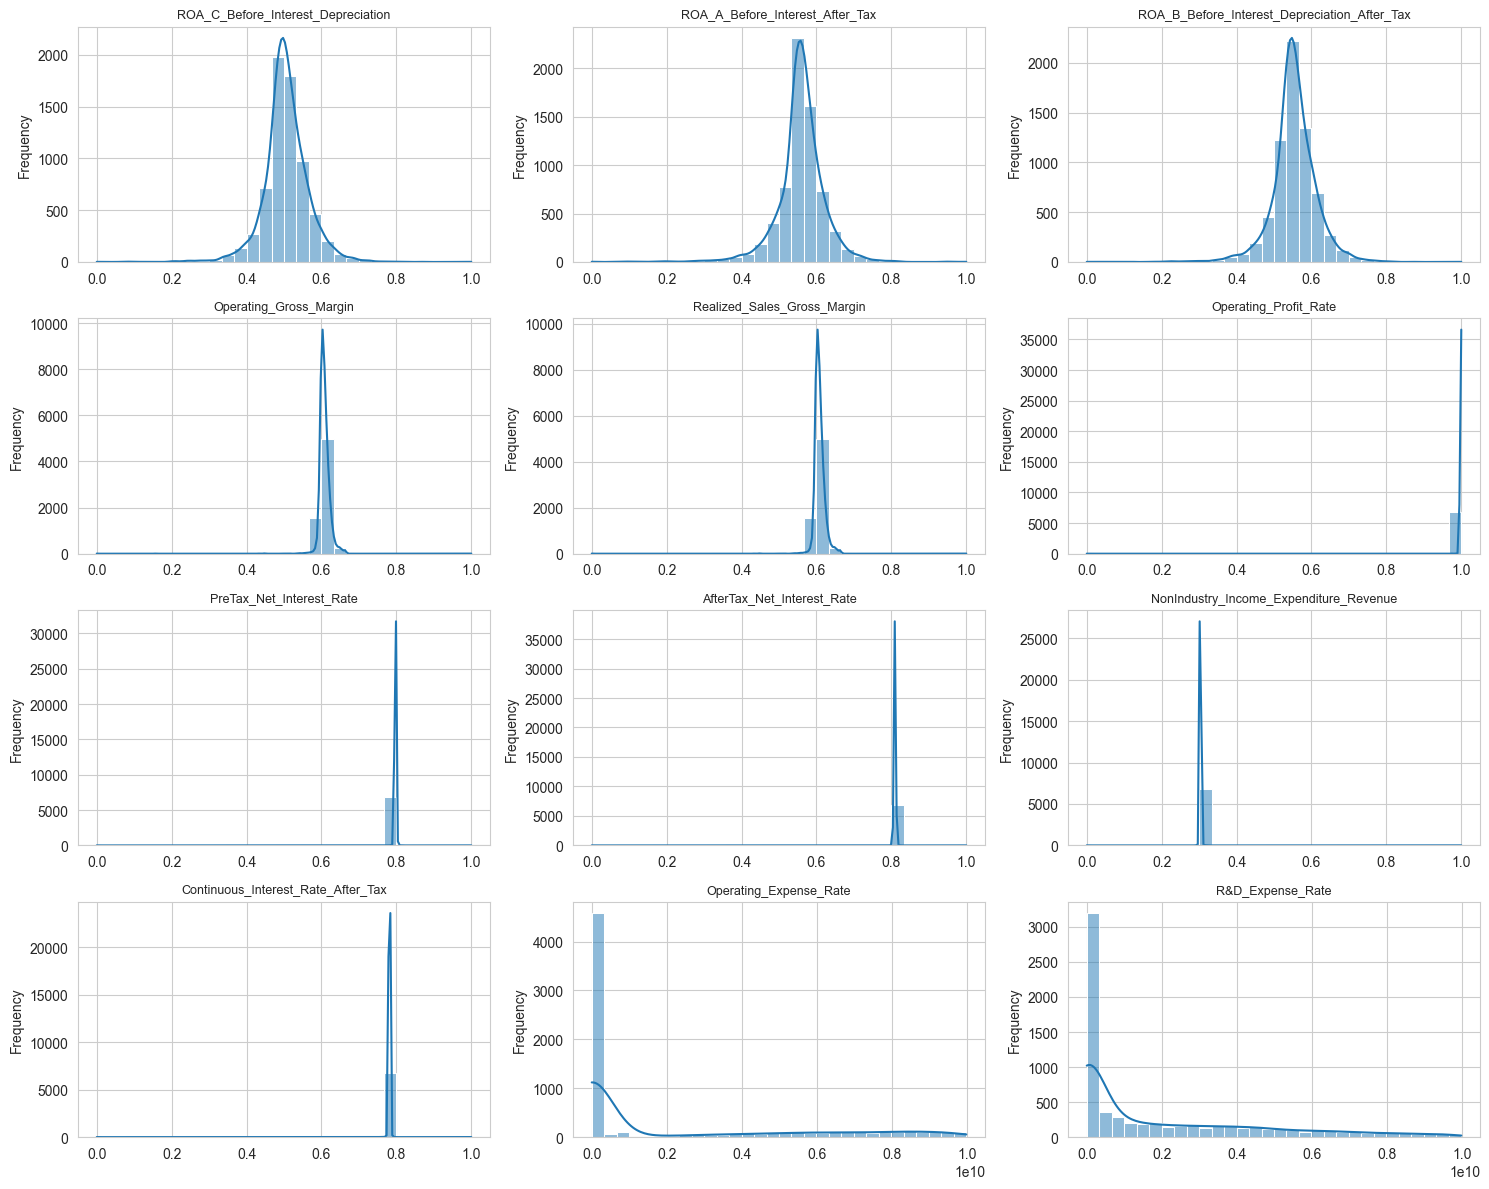

In [11]:
# Select first 12 numerical features for visualization
selected_features = numeric_cols[:12]

# Create histogram plots
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(selected_features):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Observation

The histograms show that many financial ratio features are not perfectly normally distributed.

Some features are concentrated around a small range, while others show skewness or extreme values.

This is common in financial datasets because companies can have very different financial conditions.

These distribution patterns are important because they may affect machine learning models.  
Therefore, outlier handling and feature scaling will be considered later in the data cleaning and preprocessing stage.

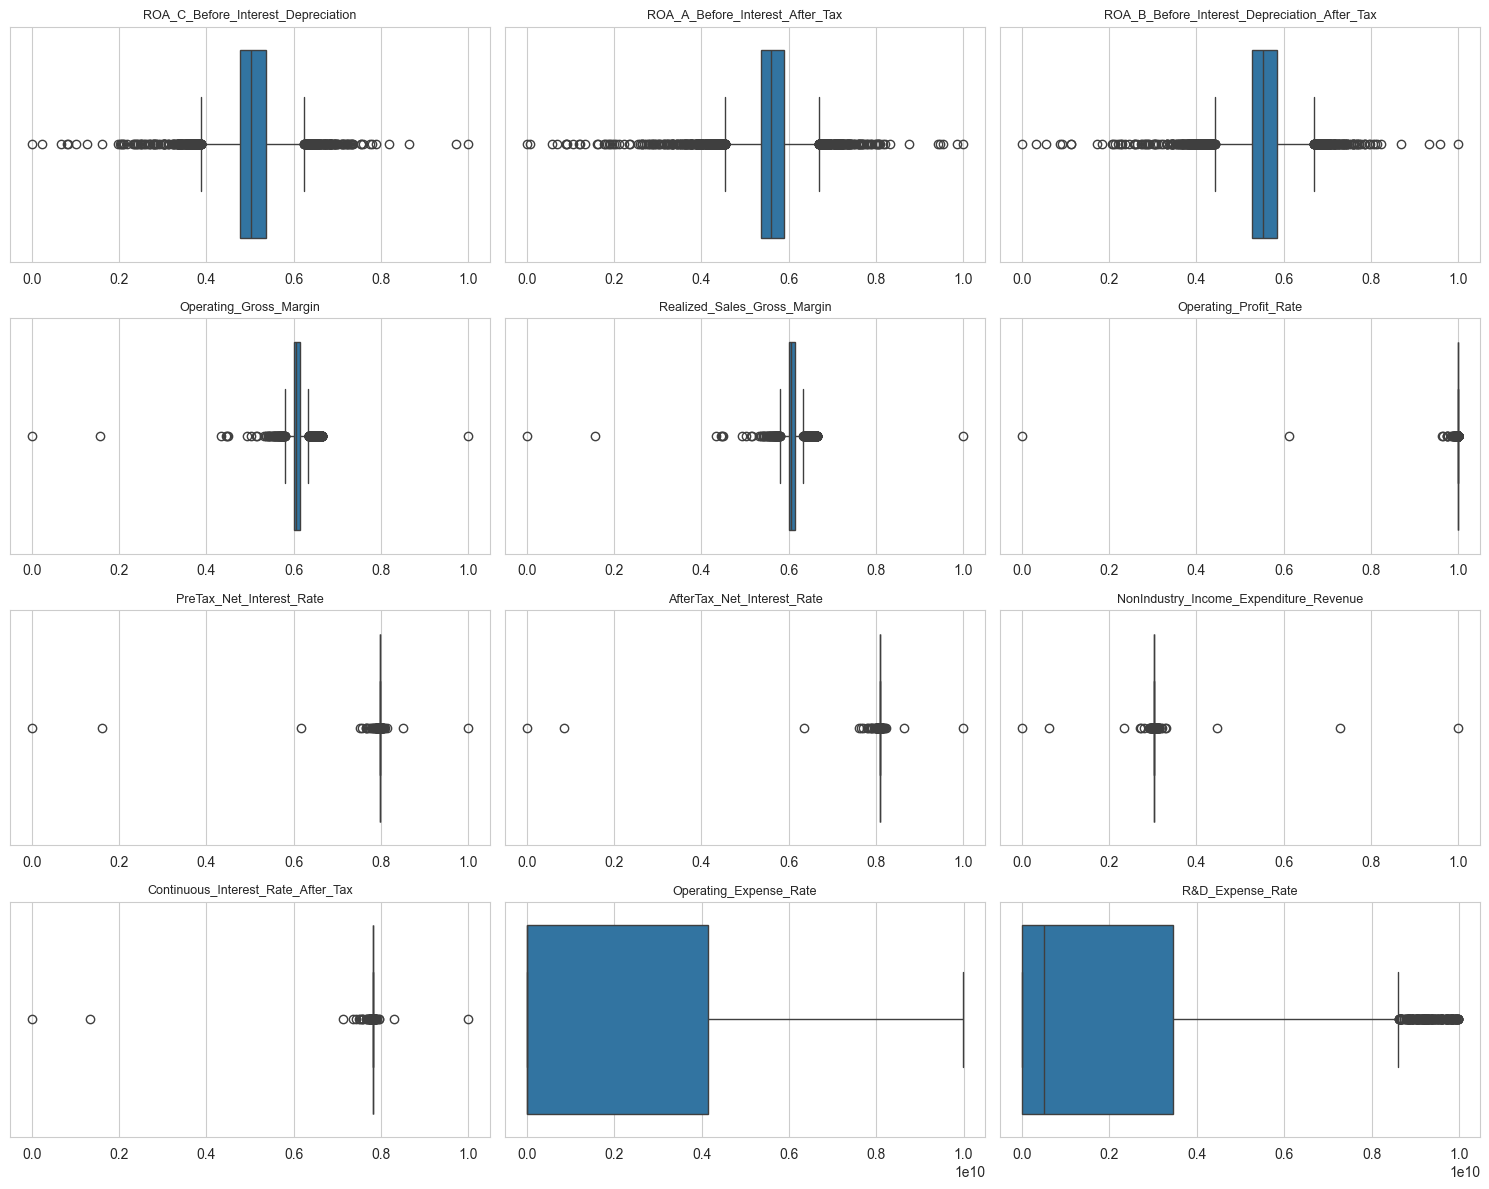

In [12]:
# Select first 12 numerical features for boxplot visualization
selected_features = numeric_cols[:12]

# Create boxplots
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(selected_features):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

### Observation

The boxplots show that several numerical features contain possible outliers.

Some values are far away from the main range of the data.  
This is common in financial datasets because companies can have very different financial conditions.

These outliers should not be removed immediately during EDA.  
Instead, they will be handled carefully during the data cleaning and preprocessing stage using suitable techniques such as outlier capping.

## 7. Bivariate Analysis — Features vs Target

In this section, we analyze the relationship between numerical features and the target variable `Bankrupt`.

We calculate the correlation between each numerical feature and the target variable.

Correlation helps us identify which financial features have the strongest relationship with bankruptcy.

A higher absolute correlation value means the feature has a stronger relationship with the target variable.

In [13]:
# Create a copy of the dataset for correlation analysis
df_corr = df.copy()

# Convert Bankrupt target column from Yes/No to 1/0 if needed
df_corr["Bankrupt"] = df_corr["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

# Make sure Bankrupt column is numeric
df_corr["Bankrupt"] = df_corr["Bankrupt"].astype(int)

# Select only numerical columns
numeric_cols_corr = df_corr.select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation with target variable
correlations = df_corr[numeric_cols_corr].corr()["Bankrupt"].abs()

# Remove target variable itself
correlations = correlations.drop("Bankrupt")

# Select top 6 features most correlated with bankruptcy
top_features = correlations.sort_values(ascending=False).head(6)

print("Top features correlated with bankruptcy:")
top_features.round(3)

Top features correlated with bankruptcy:


Net_Income_to_Total_Assets                     0.3150
ROA_A_Before_Interest_After_Tax                0.2830
ROA_B_Before_Interest_Depreciation_After_Tax   0.2730
ROA_C_Before_Interest_Depreciation             0.2610
Debt_Ratio_Percent                             0.2500
Net_Worth_to_Assets                            0.2500
Name: Bankrupt, dtype: float64

### Observation

The features shown above have the strongest correlation with the target variable `Bankrupt`.

These features may be useful for predicting whether a company is bankrupt or healthy.

However, correlation alone does not prove that a feature causes bankruptcy.  
It only shows the strength of the relationship between the feature and the target variable.

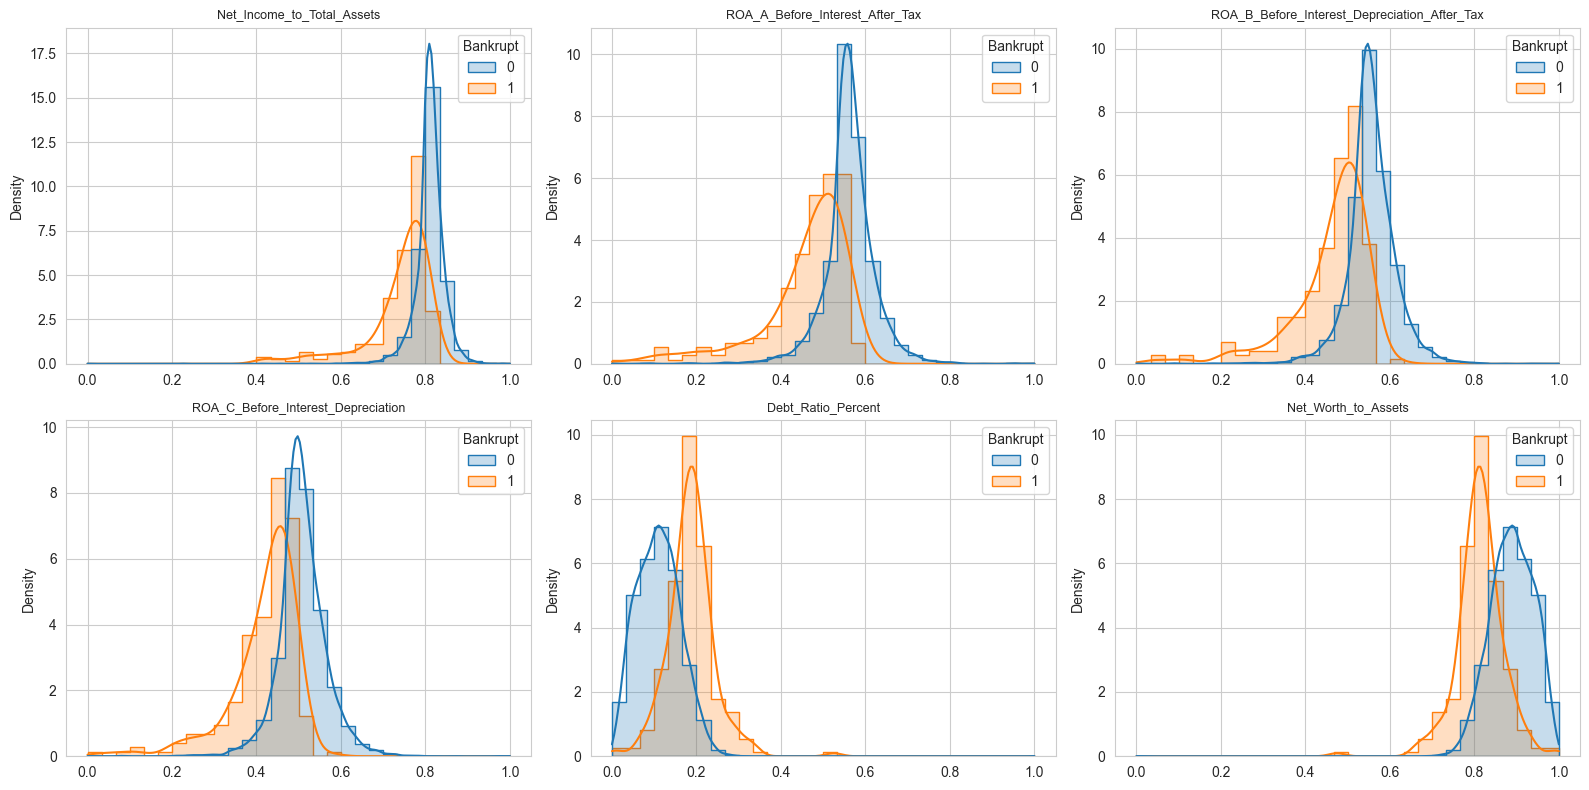

In [14]:
# Visualize the top correlated features against the target variable
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(top_features.index):
    sns.histplot(
        data=df_corr,
        x=col,
        hue="Bankrupt",
        bins=30,
        kde=True,
        ax=axes[i],
        element="step",
        stat="density",
        common_norm=False
    )
    
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Density")

plt.tight_layout()
plt.show()

### Observation

The distribution plots compare healthy and bankrupt companies for the most correlated features.

Some features show visible differences between the two target classes.  
This means these features may help the model separate bankrupt companies from healthy companies.

Because the dataset is highly imbalanced, the bankrupt class is much smaller than the healthy class.  
Using density-based histograms makes the comparison easier than using raw counts.

In [15]:
# Create a copy for safe analysis
df_mean = df.copy()

# Convert Bankrupt column to numeric if needed
df_mean["Bankrupt"] = df_mean["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_mean["Bankrupt"] = df_mean["Bankrupt"].astype(int)

# Select numerical feature columns
numeric_cols_mean = df_mean.select_dtypes(include=[np.number]).columns.tolist()

# Remove target column from feature list
if "Bankrupt" in numeric_cols_mean:
    numeric_cols_mean.remove("Bankrupt")

# Calculate mean values for each feature by target class
mean_comparison = df_mean.groupby("Bankrupt")[numeric_cols_mean].mean().T

# Rename columns for better readability
mean_comparison.columns = ["Healthy", "Bankrupt"]

# Calculate difference between bankrupt and healthy companies
mean_comparison["Difference"] = (
    mean_comparison["Bankrupt"] - mean_comparison["Healthy"]
)

# Display top 15 features with the largest absolute mean difference
mean_comparison.sort_values(
    "Difference",
    key=abs,
    ascending=False
).round(3).head(15)

,Healthy,Bankrupt,Difference
Fixed_Assets_Turnover_Frequency,975657432.9460,1996602727.2740,1020945294.3280
Total_Asset_Growth_Rate,5531602816.0330,4803016818.1820,-728585997.8510
Quick_Asset_Turnover_Rate,2147829492.3480,2640836363.6370,493006871.2890
R&D_Expense_Rate,1961922518.5640,1605623181.8180,-356299336.7450
Cash_Turnover_Rate,2481653241.5520,2181732727.2730,-299920514.2790
Cash_to_Current_Liability,29899530.2450,254940909.0940,225041378.8480
Current_Asset_Turnover_Rate,1189711557.8120,1380154000.0010,190442442.1880
Operating_Expense_Rate,1998943222.6100,1887486363.6370,-111456858.9730
Total_Assets_to_GNP_Price,16216699.5080,91000000.0110,74783300.5030
Net_Value_Growth_Rate,204576.4520,42409090.9090,42204514.4580


### Observation

The table shows the numerical features with the largest average difference between healthy and bankrupt companies.

A positive difference means the average value is higher for bankrupt companies.  
A negative difference means the average value is higher for healthy companies.

Some features show very large differences, which suggests that these financial indicators may be useful for bankruptcy prediction.

However, this table should be interpreted carefully because some features may contain extreme values or outliers.  
These issues will be handled during the data cleaning and preprocessing stage.

## 10. Correlation Analysis

In this section, we analyze the correlation between the most important numerical features.

A correlation matrix helps us understand how features are related to each other and to the target variable `Bankrupt`.

Correlation values range from:

- `1` = Strong positive relationship
- `0` = No linear relationship
- `-1` = Strong negative relationship

This step is useful because highly correlated features may contain similar information.

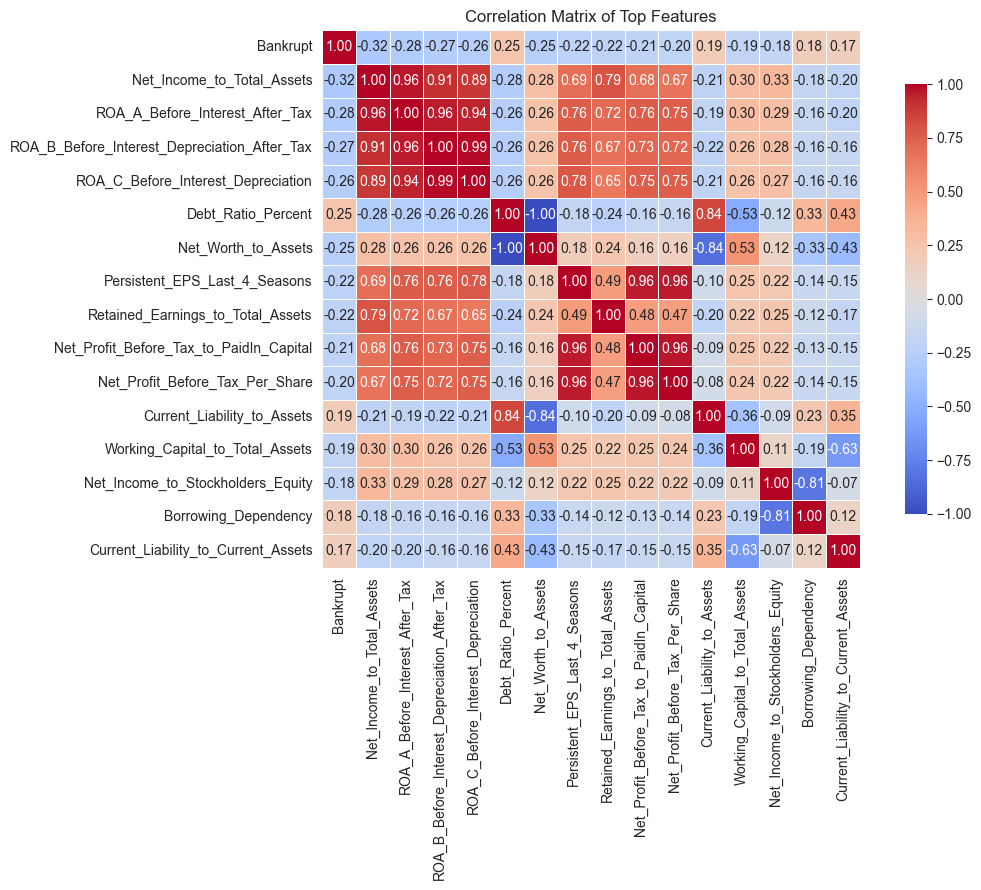

In [16]:
# Create a copy for correlation analysis
df_heatmap = df.copy()

# Convert target variable to numeric if needed
df_heatmap["Bankrupt"] = df_heatmap["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_heatmap["Bankrupt"] = df_heatmap["Bankrupt"].astype(int)

# Select only numerical columns
numeric_cols_heatmap = df_heatmap.select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation with target variable
target_corr = df_heatmap[numeric_cols_heatmap].corr()["Bankrupt"].abs()

# Select top 15 features most correlated with target
top_numeric_features = target_corr.drop("Bankrupt").sort_values(ascending=False).head(15).index.tolist()

# Add target variable to the selected features
selected_corr_features = ["Bankrupt"] + top_numeric_features

# Create correlation matrix
corr_matrix = df_heatmap[selected_corr_features].corr()

# Plot heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Matrix of Top Features")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation

The heatmap shows the correlation between the target variable and the top numerical features.

Some profitability-related features, such as ROA and net income ratios, show a noticeable relationship with bankruptcy.

Several features are also highly correlated with each other.  
For example, some ROA-related features have very strong positive correlations.

This means some features may provide similar information.  
During model building, this should be considered because highly correlated features can sometimes affect model performance or make interpretation harder.

However, no feature will be removed at this EDA stage.  
Feature selection or handling of correlated features can be considered later during preprocessing or model building.

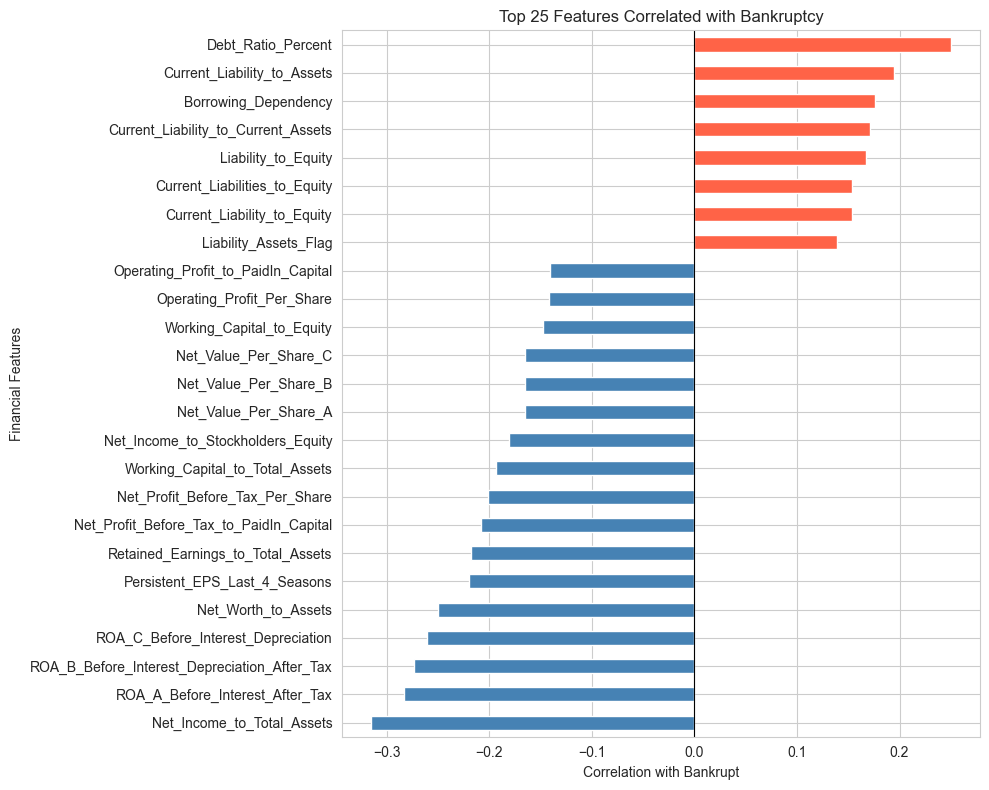

In [17]:
# Create a copy for target correlation analysis
df_target_corr = df.copy()

# Convert target variable to numeric if needed
df_target_corr["Bankrupt"] = df_target_corr["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_target_corr["Bankrupt"] = df_target_corr["Bankrupt"].astype(int)

# Select numerical columns
numeric_cols_target = df_target_corr.select_dtypes(include=[np.number]).columns.tolist()

# Remove target column from feature list
if "Bankrupt" in numeric_cols_target:
    numeric_cols_target.remove("Bankrupt")

# Calculate correlation with target
target_corr = df_target_corr[numeric_cols_target + ["Bankrupt"]].corr()["Bankrupt"]

# Remove target itself
target_corr = target_corr.drop("Bankrupt")

# Select top 25 features by absolute correlation
top_target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).head(25).index
).sort_values()

# Plot correlation bar chart
plt.figure(figsize=(10, 8))

colors = ["steelblue" if value < 0 else "tomato" for value in top_target_corr]

top_target_corr.plot(kind="barh", color=colors)

plt.title("Top 25 Features Correlated with Bankruptcy")
plt.xlabel("Correlation with Bankrupt")
plt.ylabel("Financial Features")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

### Observation

The chart shows the top numerical features most correlated with bankruptcy.

Features on the right side have a positive relationship with bankruptcy, while features on the left side have a negative relationship.

Liability-related features show positive correlation with bankruptcy, meaning higher liability levels may be associated with higher bankruptcy risk.

Profitability and asset-related features show negative correlation, meaning stronger profitability or asset performance may be associated with lower bankruptcy risk.

However, correlation only shows relationships.  
It does not prove that one feature directly causes bankruptcy.

## 12. Domain Deep-Dive — Key Financial Indicators

In this section, we compare important financial indicators between healthy and bankrupt companies.

The selected features are the top features most correlated with the target variable.

Boxplots are used to compare the distribution of each feature for:

- `0` = Healthy company
- `1` = Bankrupt company

This helps us understand how financial ratios differ between the two groups.

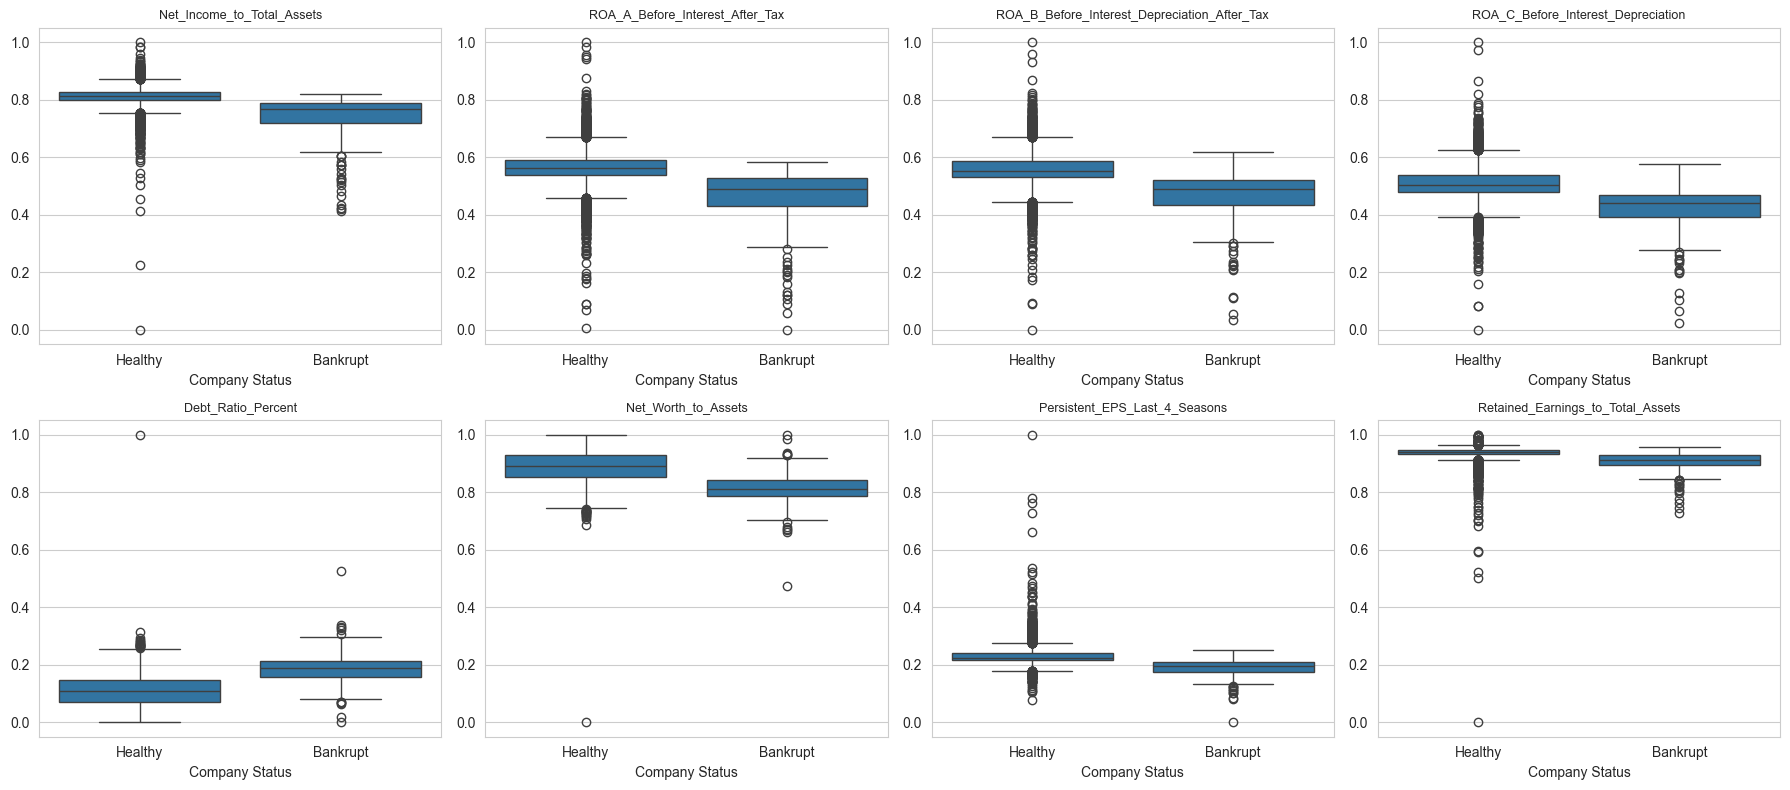

In [18]:
# Create a copy for domain deep-dive analysis
df_domain = df.copy()

# Convert target variable to numeric if needed
df_domain["Bankrupt"] = df_domain["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_domain["Bankrupt"] = df_domain["Bankrupt"].astype(int)

# Select numerical columns
numeric_cols_domain = df_domain.select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation with target
domain_corr = df_domain[numeric_cols_domain].corr()["Bankrupt"].abs()

# Select top 8 features most correlated with bankruptcy
top_domain_features = (
    domain_corr
    .drop("Bankrupt")
    .sort_values(ascending=False)
    .head(8)
    .index
    .tolist()
)

# Create boxplots for top features
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(top_domain_features):
    sns.boxplot(
        data=df_domain,
        x="Bankrupt",
        y=col,
        ax=axes[i]
    )
    
    axes[i].set_title(col[:45], fontsize=9)
    axes[i].set_xlabel("Company Status")
    axes[i].set_ylabel("")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Healthy", "Bankrupt"])

plt.tight_layout()
plt.show()

### Observation

The boxplots show clear differences between healthy and bankrupt companies for several important financial indicators.

Profitability-related features such as ROA and net income ratios are generally lower for bankrupt companies.

Leverage-related features such as debt ratio are generally higher for bankrupt companies.

This suggests that companies with weaker profitability and higher debt levels are more likely to be associated with bankruptcy.

Some features also contain many outliers, which is common in financial datasets.  
These outliers should be handled carefully during the data cleaning and preprocessing stage.

In [19]:
# Create a copy for class imbalance summary
df_imbalance = df.copy()

# Convert target variable to numeric if needed
df_imbalance["Bankrupt"] = df_imbalance["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_imbalance["Bankrupt"] = df_imbalance["Bankrupt"].astype(int)

# Calculate class counts
total_records = len(df_imbalance)
bankrupt_count = df_imbalance["Bankrupt"].sum()
healthy_count = total_records - bankrupt_count

# Calculate percentages
healthy_percentage = healthy_count / total_records * 100
bankrupt_percentage = bankrupt_count / total_records * 100

# Calculate imbalance ratio
imbalance_ratio = healthy_count / bankrupt_count

print(f"Healthy companies   : {healthy_count} ({healthy_percentage:.2f}%)")
print(f"Bankrupt companies  : {bankrupt_count} ({bankrupt_percentage:.2f}%)")
print(f"Imbalance ratio     : {imbalance_ratio:.1f}:1")

Healthy companies   : 6599 (96.77%)
Bankrupt companies  : 220 (3.23%)
Imbalance ratio     : 30.0:1


### Observation

The dataset is highly imbalanced.

There are **6,599 healthy companies** and only **220 bankrupt companies**.

This means approximately:

- **96.77%** of companies are healthy
- **3.23%** of companies are bankrupt

The imbalance ratio is about **30:1**, meaning there are around 30 healthy companies for every 1 bankrupt company.

This is an important issue for machine learning.  
If the model is not handled carefully, it may become biased toward predicting companies as healthy.

Therefore, during model building, accuracy alone will not be enough.  
We should also use evaluation metrics such as:

- Precision
- Recall
- F1-score
- ROC-AUC score

## 14. Pair Plot of Top Features

In this section, we create a pair plot using the top correlated features.

A pair plot helps us understand:

- Relationships between selected numerical features
- Distribution of each feature
- Possible separation between healthy and bankrupt companies

Since pair plots can be slow with large datasets, we use a sample of the dataset for better performance.

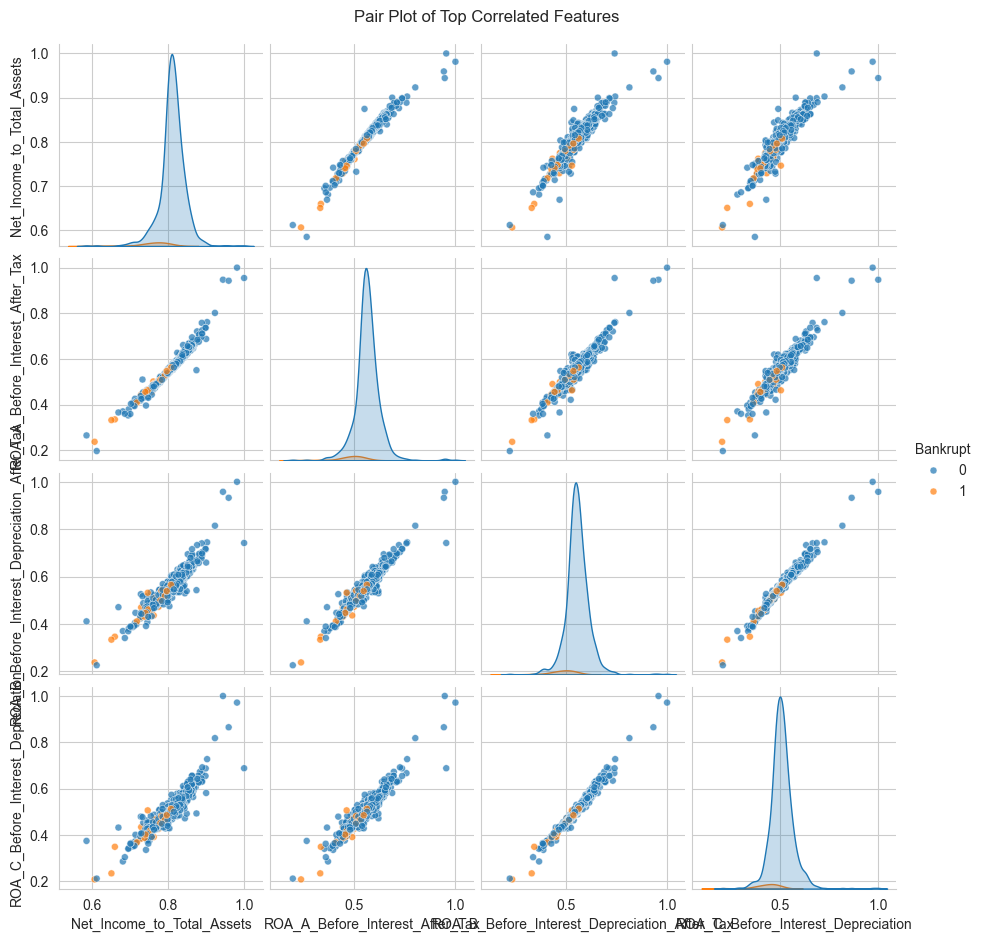

In [20]:
# Create a copy for pair plot analysis
df_pair = df.copy()

# Convert target variable to numeric if needed
df_pair["Bankrupt"] = df_pair["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_pair["Bankrupt"] = df_pair["Bankrupt"].astype(int)

# Select top 4 features from the previous correlation analysis
pair_features = list(top_features.index[:4])

# Take a sample to make the pair plot faster and easier to read
sample_df = df_pair[pair_features + ["Bankrupt"]].sample(
    n=min(1000, len(df_pair)),
    random_state=42
)

# Create pair plot
pair_plot = sns.pairplot(
    sample_df,
    vars=pair_features,
    hue="Bankrupt",
    diag_kind="kde",
    height=2.3,
    plot_kws={"alpha": 0.7, "s": 25}
)

pair_plot.fig.suptitle("Pair Plot of Top Correlated Features", y=1.02)

plt.show()

### Observation

The pair plot shows relationships between the top correlated financial features.

Several selected features show strong linear relationships with each other.  
This means some features may contain similar information.

The bankrupt class is much smaller than the healthy class, so the bankrupt points are less visible in the plot.

This confirms the class imbalance issue identified earlier.

The pair plot is useful for understanding feature relationships, but final feature decisions should be made during preprocessing and model building.

## 15. Summary of Key Findings

This section summarizes the main findings from the Exploratory Data Analysis.

The purpose of this summary is to clearly highlight the most important observations before moving to data cleaning and preprocessing.

In [21]:
# Create a copy for final EDA summary
df_summary = df.copy()

# Convert target variable to numeric if needed
df_summary["Bankrupt"] = df_summary["Bankrupt"].replace({
    "No": 0,
    "Yes": 1,
    "no": 0,
    "yes": 1
})

df_summary["Bankrupt"] = df_summary["Bankrupt"].astype(int)

# Calculate key summary values
total_samples = len(df_summary)
total_features = df_summary.shape[1] - 1

healthy_count = int((df_summary["Bankrupt"] == 0).sum())
bankrupt_count = int((df_summary["Bankrupt"] == 1).sum())

healthy_percentage = healthy_count / total_samples * 100
bankrupt_percentage = bankrupt_count / total_samples * 100

imbalance_ratio = healthy_count / bankrupt_count

# Calculate top correlated feature
numeric_cols_summary = df_summary.select_dtypes(include=[np.number]).columns.tolist()

target_correlations = (
    df_summary[numeric_cols_summary]
    .corr()["Bankrupt"]
    .drop("Bankrupt")
    .abs()
    .sort_values(ascending=False)
)

top_correlated_feature = target_correlations.index[0]
top_correlation_value = target_correlations.iloc[0]

# Create summary table
eda_summary = pd.DataFrame({
    "Metric": [
        "Total samples",
        "Total features",
        "Healthy companies",
        "Bankrupt companies",
        "Healthy percentage",
        "Bankrupt percentage",
        "Class imbalance ratio",
        "Top correlated feature",
        "Top correlation value"
    ],
    "Value": [
        total_samples,
        total_features,
        healthy_count,
        bankrupt_count,
        f"{healthy_percentage:.2f}%",
        f"{bankrupt_percentage:.2f}%",
        f"{imbalance_ratio:.1f}:1",
        top_correlated_feature,
        round(top_correlation_value, 3)
    ]
})

eda_summary

,Metric,Value
0,Total samples,6819
1,Total features,94
2,Healthy companies,6599
3,Bankrupt companies,220
4,Healthy percentage,96.77%
5,Bankrupt percentage,3.23%
6,Class imbalance ratio,30.0:1
7,Top correlated feature,Net_Income_to_Total_Assets
8,Top correlation value,0.3150


### Final EDA Summary

The Exploratory Data Analysis shows that the dataset contains **6,819 company records** and **94 financial features**.

The target variable is `Bankrupt`, where:

- `0` represents a healthy company
- `1` represents a bankrupt company

The dataset is highly imbalanced.  
There are **6,599 healthy companies** and only **220 bankrupt companies**.

This means only about **3.23%** of the companies are bankrupt.

The analysis also showed that several financial features have noticeable relationships with bankruptcy.  
Profitability-related features such as net income and ROA ratios tend to be lower for bankrupt companies, while liability-related features tend to be higher.

The dataset also contains outliers and skewed numerical features, which are common in financial data.

These findings show that proper preprocessing is important before model building.

In the next notebook, we will focus on:

- Handling invalid values
- Handling outliers
- Preparing features and target variable
- Scaling numerical features
- Saving cleaned data for model building